# 🧠 Lesson 1: Introduction to Machine Learning
**Week 5 · Notebook 1 of 10 · ⏱️ about 90 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Explain** what machine learning is, and how it differs from ordinary programming.
2. **Distinguish** supervised, unsupervised and reinforcement learning, and recognise which one a real problem needs.
3. **Identify** features and target variables in a dataset and separate them in code.
4. **Describe** the machine-learning workflow from problem to deployment.
5. **Differentiate** *training* from *inference*, and run both with scikit-learn.
6. **Tell apart** model **parameters** (learned) from **hyperparameters** (chosen).

## 📋 Prerequisites
Basic Python, a little NumPy and pandas. If `df["col"].mean()` makes sense to you, you're ready.

## 🗺️ Roadmap
`Rules vs. examples` → `Definition` → `Types of ML` → `Features & target` → `The workflow` → `Training vs inference` → `Parameters vs hyperparameters` → **Problems** → Exit ticket

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor

---
# 📖 Part 1: Rules vs. examples

Imagine I ask you to write a program that converts **Celsius to Fahrenheit**.

You'd probably do this:

```python
def c_to_f(c):
    return 1.8 * c + 32      # <- a RULE that a human discovered and typed in
```

That's **traditional programming**:  `rules + data  →  answers`.

Now imagine a world where nobody has told you the rule. All you have is a notebook of measurements:

| Celsius | Fahrenheit |
|---|---|
| -40 | -40 |
| 0 | 32 |
| 37 | 98.6 |
| 100 | 212 |

Could a computer *discover* the rule from these examples? That's **machine learning**: `data + answers  →  rules`.

Let's watch it happen.

In [2]:
# Our "notebook of measurements"
celsius    = np.array([-40, -10, 0, 15, 25, 37, 100]).reshape(-1, 1)   # inputs  (must be 2-D for sklearn)
fahrenheit = np.array([-40,  14, 32, 59, 77, 98.6, 212])               # answers

model = LinearRegression()     # a model that can learn straight-line relationships
model.fit(celsius, fahrenheit) # <- LEARNING happens here

print(f"The machine discovered:  F = {model.coef_[0]:.2f} x C + {model.intercept_:.2f}")
print(f"Prediction for 50 °C  ->  {model.predict([[50]])[0]:.1f} °F   (true answer: 122 °F)")

The machine discovered:  F = 1.80 x C + 32.00
Prediction for 50 °C  ->  122.0 °F   (true answer: 122 °F)


Nobody typed `1.8` or `32`. The computer **found** them. Remember this moment: everything in this course is a variation on this one idea.

| | Traditional programming | Machine learning |
|---|---|---|
| **You provide** | rules + data | data + answers (examples) |
| **Computer produces** | answers | rules (a *model*) |
| **Best when** | the rules are known and simple | the rules are unknown, too complex to write, or change over time |
| **Example** | tax calculator | spam filter, recommendations, translation |

> 💡 **Why bother?** Try writing explicit rules to recognise a cat in a photo, or to detect spam. You'll quickly drown in exceptions. It's *much* easier to show 100,000 labelled examples and let the algorithm find the pattern.

---
## 📖 Part 2: A precise definition

Computer scientist **Tom Mitchell** gave the classic definition (1997):

> *A program is said to **learn** from experience **E** with respect to some task **T** and performance measure **P**, if its performance at **T**, as measured by **P**, improves with experience **E**.*

It sounds abstract, so let's fill in the blanks for three real systems:

| System | Task **T** | Experience **E** | Performance **P** |
|---|---|---|---|
| Spam filter | classify emails as spam / not spam | thousands of emails labelled by users | % classified correctly |
| House-price estimator | predict a sale price | past sales with their prices | average error in dollars |
| Chess engine | win games | millions of games played against itself | win rate |

**Whenever you meet a new ML problem, ask: what are T, E, and P?** If you can't answer, you're not ready to code yet.

---
## 📖 Part 3: The three families of machine learning

| Family | The data contains… | The goal | Everyday analogy |
|---|---|---|---|
| **Supervised** | inputs **and** correct answers (*labels*) | predict the answer for new inputs | studying with an answer key |
| **Unsupervised** | inputs only | discover hidden structure | sorting a pile of unlabeled photos into piles that "feel" similar |
| **Reinforcement** | an agent acting in an environment, receiving rewards | learn actions that maximise reward | training a dog with treats |

Supervised learning splits again, by *what kind of answer* we predict:

* **Regression**: predict a **number** (price, temperature, exam score).
* **Classification**: predict a **category** (spam / not spam, cat / dog / bird).

Unsupervised learning also has two classic flavours: **clustering** (group similar things) and **dimensionality reduction** (compress many features into few).

*In this course we focus on supervised and unsupervised learning: they power most real-world ML. Reinforcement learning gets a course of its own later.*

Let's *see* the difference on the very same points.

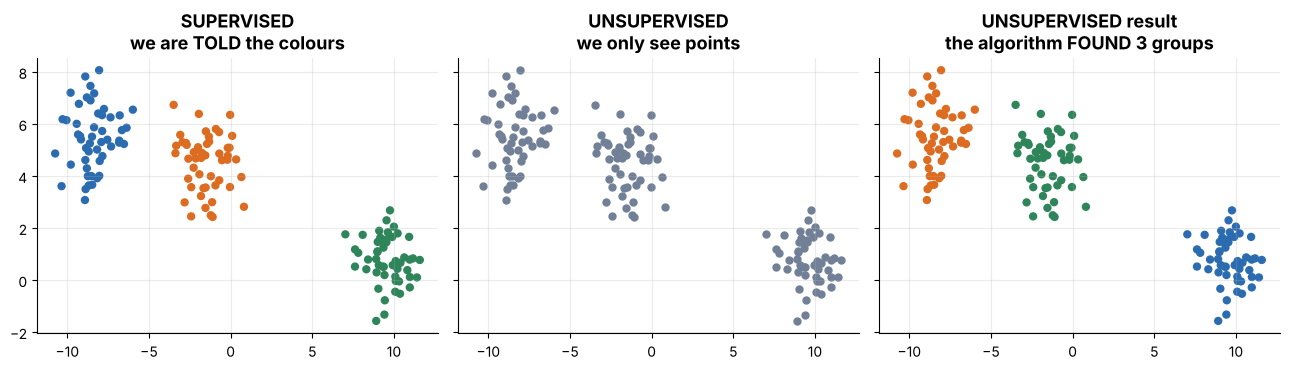

In [3]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

pts, true_labels = make_blobs(n_samples=150, centers=3, cluster_std=1.1, random_state=7)
found = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(pts)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
axes[0].scatter(*pts.T, c=[PALETTE[i] for i in true_labels], s=25)
axes[0].set_title("SUPERVISED\nwe are TOLD the colours")
axes[1].scatter(*pts.T, c=GREY, s=25)
axes[1].set_title("UNSUPERVISED\nwe only see points")
axes[2].scatter(*pts.T, c=[PALETTE[i] for i in found], s=25)
axes[2].set_title("UNSUPERVISED result\nthe algorithm FOUND 3 groups")
plt.tight_layout(); plt.show()

### 🤔 Pause & Predict
For each task, decide: *supervised or unsupervised?* If supervised, *regression or classification?*

1. Predict the number of minutes a delivery will take.
2. Group Spotify listeners into "taste communities" (no one has named the communities).
3. Decide whether an X-ray shows pneumonia, given thousands of X-rays labelled by radiologists.

<details><summary>👀 Answers</summary>

1. **Supervised → regression** (the answer is a number).
2. **Unsupervised → clustering** (no labels exist).
3. **Supervised → classification** (the answer is a category: pneumonia / healthy).

</details>

---
## 📖 Part 4: Features and target variables

Let's open a real dataset. Each row is one house that sold; each column is one fact about it.

In [4]:
housing = load("housing.csv")
print(f"{housing.shape[0]} houses, {housing.shape[1]} columns")
housing.head()

900 houses, 8 columns


,area_sqm,bedrooms,bathrooms,age_years,distance_to_center_km,has_garden,neighborhood_quality,price_k
0,127.6,2,1,39,4.8,1,3,504.0
1,99.1,1,1,23,20.9,1,3,367.8
2,103.5,2,1,7,1.1,1,4,515.9
3,40.0,1,1,54,8.2,1,5,218.7
4,192.0,5,2,9,39.0,0,4,644.3


### The vocabulary you must own

| Everyday word | ML words | In our table |
|---|---|---|
| one row | **sample**, example, observation, instance | one house |
| input columns | **features**, predictors, attributes, independent variables | `area_sqm`, `bedrooms`, `age_years`, … |
| the column we want to predict | **target**, label, response, dependent variable | `price_k` (price in $1000s) |

By convention (and in every textbook):

* **`X`** (capital) = the table of features, shape `(n_samples, n_features)`: a *matrix*.
* **`y`** (lowercase) = the target, shape `(n_samples,)`: a *vector*.

The model learns a function **`ŷ = f(X)`** where the little hat on `ŷ` ("y-hat") means *"our prediction"*, as opposed to the true `y`.

In [5]:
target_col = "price_k"

X = housing.drop(columns=target_col)    # everything EXCEPT the target
y = housing[target_col]                 # only the target

print("X (features) shape:", X.shape, "  <- n_samples x n_features")
print("y (target)   shape:", y.shape)
print("\nFeature names:", list(X.columns))

X (features) shape: (900, 7)   <- n_samples x n_features
y (target)   shape: (900,)

Feature names: ['area_sqm', 'bedrooms', 'bathrooms', 'age_years', 'distance_to_center_km', 'has_garden', 'neighborhood_quality']


> ⚠️ **Golden rule:** the target must **never** be inside `X`. If it is, the model can just copy the answer and will look brilliant: right up until you use it on a house whose price you don't know. (We'll see this "data leakage" disaster in Lesson 4.)

### 🧑‍🏫 Worked Example 1: Framing a problem like a professional

> **A phone company wants to know which customers are about to cancel, so it can offer them a discount.** Let's frame it.

1. **What are we predicting?** Whether a customer *churns* (leaves). That's a **yes/no** answer → **classification**.
2. **Do we have labelled history?** Yes, past customers who did or didn't leave → **supervised**.
3. **What are the features?** Anything known *before* the customer leaves: tenure, monthly bill, support calls, contract type…
4. **What's the target?** `churned` (1 = left, 0 = stayed).
5. **Performance P?** Not plain accuracy: only ~15% of customers leave! (Lesson 7 explains why that matters.)

Let's check our reasoning on the real data:

In [6]:
churn = load("churn.csv")
X_churn = churn.drop(columns="churned")
y_churn = churn["churned"]

print("Features:", list(X_churn.columns))
print("\nClass balance (target):")
print(y_churn.value_counts(normalize=True).rename({0: "stayed", 1: "churned"}).round(3))

Features: ['tenure_months', 'monthly_charge', 'support_calls', 'contract_months', 'late_payments', 'usage_gb']

Class balance (target):
churned
stayed     0.848
churned    0.152
Name: proportion, dtype: float64


Good: our framing matches reality, and the class balance warns us that **accuracy alone will mislead us**. A model that *always* says "stayed" would be 85% accurate and completely useless. Great framing catches problems like this *before* any modelling.

---
## 📖 Part 5: The machine-learning workflow

Machine learning is not "call `.fit()` and go home". It's a **loop**. Here is the map we'll follow all course (and all career):

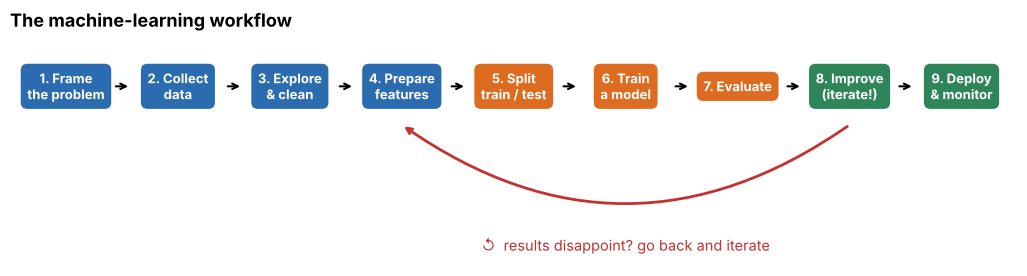

In [7]:
steps = ["1. Frame\nthe problem", "2. Collect\ndata", "3. Explore\n& clean", "4. Prepare\nfeatures",
         "5. Split\ntrain / test", "6. Train\na model", "7. Evaluate", "8. Improve\n(iterate!)", "9. Deploy\n& monitor"]
fig, ax = plt.subplots(figsize=(13, 3.0)); ax.axis("off"); ax.set_xlim(0, 9); ax.set_ylim(0, 1.8)
for i, s in enumerate(steps):
    x = i
    color = PALETTE[0] if i < 4 else (PALETTE[1] if i < 7 else PALETTE[2])
    ax.text(x + 0.5, 1.4, s, ha="center", va="center", fontsize=9.5, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc=color, ec="none"))
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 1.08, 1.4), xytext=(x + 0.92, 1.4), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("", xy=(3.5, 1.1), xytext=(7.5, 1.1),
            arrowprops=dict(arrowstyle="->", lw=2, color=RED, connectionstyle="arc3,rad=-0.35"))
ax.text(5.5, 0.12, "↺  results disappoint? go back and iterate", color=RED, ha="center", fontsize=10.5)
ax.set_title("The machine-learning workflow", loc="left")
plt.show()

| Stage | The question you're answering | Where in this course |
|---|---|---|
| **Frame** | What are T, E, P? Is ML even needed? | Lesson 1 |
| **Collect** | Where does labelled data come from? What does it cost? | Lesson 2 |
| **Explore & clean** | Missing values? Outliers? Surprises? | Capstone |
| **Prepare features** | Scale, encode, create new features | Lessons 3, 8, Capstone |
| **Split** | How do I keep an honest "final exam"? | Lesson 4 |
| **Train** | Which model? Fit it to the training data | Lessons 2, 4, 8 |
| **Evaluate** | How good is it *on data it has never seen*? | Lessons 6, 7 |
| **Improve** | Overfitting? Underfitting? Tune, regularize | Lesson 5 |
| **Deploy & monitor** | Is it still accurate next month? | beyond this course |

> 🧑‍🏫 *Rule of thumb from industry:* **70–80% of real ML work is steps 1–4**, not step 6. Model choice is the fun 10%.

---
## 📖 Part 6: Training vs. inference

Two words you'll hear every day:

* **Training** (a.k.a. *fitting*, *learning*): the model studies labelled examples and adjusts itself. Slow, done once (or periodically). In scikit-learn → **`model.fit(X, y)`**.
* **Inference** (a.k.a. *prediction*): the trained model is handed **new** inputs and produces answers. Fast, done constantly. In scikit-learn → **`model.predict(X_new)`**.

> 🍳 **Analogy:** training is *attending cooking school* for years; inference is *cooking dinner tonight* from a recipe you already know.

### 🧑‍🏫 Worked Example 2: Your first complete model

**Question:** *Can we predict a student's exam score from the hours they studied?*

I'll narrate my thinking at each step.

In [8]:
students = load("students.csv")

# Step 1: separate features and target.  sklearn wants X to be 2-D (a table), hence the double brackets [[ ]].
X = students[["hours_studied"]]
y = students["exam_score"]

# Step 2: choose a model and TRAIN it.
model = LinearRegression()
model.fit(X, y)

# Step 3: look at what it learned.  These two numbers ARE the model.
slope, intercept = model.coef_[0], model.intercept_
print(f"Learned rule:  exam_score ≈ {intercept:.1f} + {slope:.2f} × hours_studied")

# Step 4: INFERENCE on students the model has never seen.
new_students = pd.DataFrame({"hours_studied": [1, 4, 8]})
print("\nPredictions:")
for h, p in zip(new_students["hours_studied"], model.predict(new_students)):
    print(f"  studies {h} h  ->  predicted score {p:.1f}")

Learned rule:  exam_score ≈ 35.0 + 3.98 × hours_studied

Predictions:
  studies 1 h  ->  predicted score 39.0
  studies 4 h  ->  predicted score 50.9
  studies 8 h  ->  predicted score 66.8


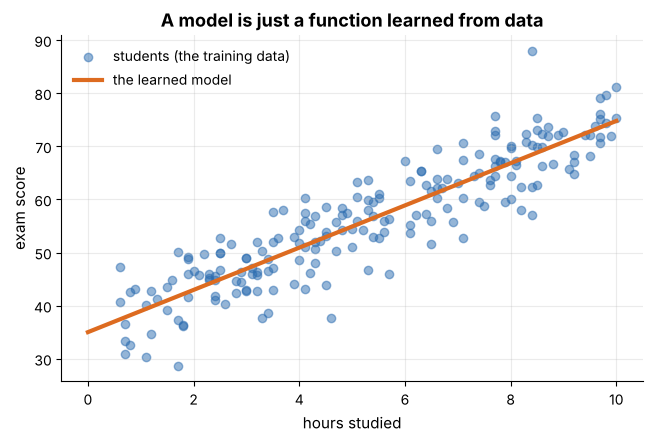

In [9]:
plt.scatter(X["hours_studied"], y, alpha=0.5, label="students (the training data)")
xs = pd.DataFrame({"hours_studied": np.linspace(0, 10, 50)})
plt.plot(xs["hours_studied"], model.predict(xs), color=ORANGE, lw=3, label="the learned model")
plt.xlabel("hours studied"); plt.ylabel("exam score"); plt.title("A model is just a function learned from data")
plt.legend(); plt.show()

**What did we just learn?**
* Read the printed rule above: the **slope** is how many extra points each additional hour of study is associated with, and the **intercept** is the score the model expects for a student who studies zero hours.
* The line doesn't hit every dot. The vertical gaps are **errors** (residuals). Measuring them well is the whole subject of Lessons 6–7.
* **The model *is* its learned numbers**: `slope` and `intercept`. Training = finding good numbers. Inference = plugging new inputs into the formula.

> ⚠️ *Honest caveat:* "associated with" ≠ "caused by". The model found a pattern, not a law of nature.

---
## 📖 Part 7: Parameters vs. hyperparameters

This distinction trips up almost everybody, so let's nail it with the study analogy:

> You're preparing for an exam. **How many hours per day you plan to study, and whether you use flashcards or re-read the textbook** are decisions *you* make **before** studying. Those are **hyperparameters**. **What ends up in your head** is what you *learned* from studying. Those are **parameters**.

| | **Parameters** | **Hyperparameters** |
|---|---|---|
| Who sets them? | the **algorithm**, during training | **you** (the human), before training |
| Learned from data? | ✅ yes | ❌ no |
| Examples | slope & intercept of a line · weights of a neural network | number of neighbours *k* · learning rate · tree depth · regularization strength |
| In scikit-learn | attributes ending in `_` (`coef_`, `intercept_`) | arguments to the constructor (`Ridge(alpha=1.0)`) |
| How to choose | `fit()` finds them | try several, compare on validation data (Lessons 4–5) |

A handy trick: **if it ends with an underscore after `fit`, it was learned (parameter). If you typed it in the constructor, it's a hyperparameter.**

In [10]:
model = Ridge(alpha=2.0)             # alpha is a HYPERPARAMETER: we chose it
print("Hyperparameters (chosen by us):", model.get_params())

model.fit(housing[["area_sqm", "age_years"]], housing["price_k"])
print("\nParameters (learned from data):")
print("  coef_      =", model.coef_.round(3))
print("  intercept_ =", round(model.intercept_, 2))

Hyperparameters (chosen by us): {'alpha': 2.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}

Parameters (learned from data):
  coef_      = [ 3.901 -1.834]
  intercept_ = 70.18


Hyperparameters change **how the model behaves**. Look how the hyperparameter *k* (number of neighbours) reshapes a K-Nearest-Neighbours regressor: it predicts by averaging the *k* closest students:

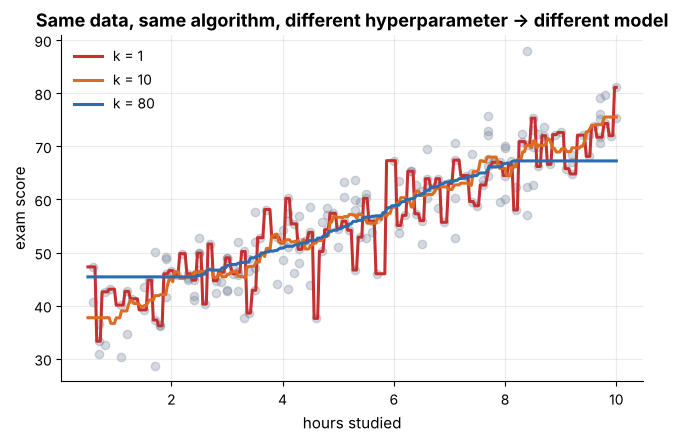

In [11]:
Xs, ys = students[["hours_studied"]], students["exam_score"]
grid = pd.DataFrame({"hours_studied": np.linspace(0.5, 10, 300)})

plt.scatter(Xs["hours_studied"], ys, alpha=0.3, color=GREY)
for k, c in [(1, RED), (10, ORANGE), (80, BLUE)]:
    knn = KNeighborsRegressor(n_neighbors=k).fit(Xs, ys)
    plt.plot(grid["hours_studied"], knn.predict(grid), color=c, lw=2.2, label=f"k = {k}")
plt.xlabel("hours studied"); plt.ylabel("exam score"); plt.legend()
plt.title("Same data, same algorithm, different hyperparameter → different model")
plt.show()

* **k = 1** (red): jumpy: the model memorises every single dot, noise included.
* **k = 80** (blue): very smooth: maybe *too* smooth, it may miss real structure.
* **k = 10** (orange): somewhere in between.

Which *k* is best? We can't answer that by staring at the training data. We need honest evaluation on unseen data: the subject of Lessons 4 and 5. For now, just notice: **hyperparameters are the knobs, and the knobs matter.**

---
# 🧩 Your turn: Problems
Open hints one at a time. Run the self-check cell after each problem.

### 🧩 Problem 1.1: Features and target in the churn data &nbsp; ⭐

Load `churn.csv`. Separate it into a **feature table `X`** and a **target vector `y`**, where the target is the `churned` column.

Afterwards: `X` must have **6 columns** and must **not** contain `churned`; `y` must be the `churned` column.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`DataFrame.drop(columns="name")` returns a copy *without* a column.

</details>

<details>
<summary>💡 Hint 2</summary>

```python
X = churn.drop(columns="churned")
y = churn["churned"]
```

</details>

In [ ]:
churn = load("churn.csv")

X = None
y = None
print(X.shape, y.shape) if X is not None else print("write your code above")

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("X has 6 feature columns", lambda: X.shape == (1500, 6))
check("target is NOT inside X", lambda: "churned" not in X.columns)
check("y is the churned column", lambda: y.name == "churned" and len(y) == 1500)

### 🧩 Problem 1.2: Train, then infer &nbsp; ⭐

Using `students.csv`, train a `LinearRegression` that predicts `exam_score` from **`hours_studied`** only.

Then use it to predict the exam score for students who studied **2, 5 and 8 hours**, and store the three predictions (a NumPy array) in a variable named `preds`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Features must be 2-D: `students[["hours_studied"]]` (double brackets).

</details>

<details>
<summary>💡 Hint 2</summary>

For the new students build a DataFrame with the *same column name*: `pd.DataFrame({"hours_studied": [2, 5, 8]})`.

</details>

<details>
<summary>💡 Hint 3</summary>

Training = `model.fit(X, y)`. Inference = `model.predict(new_data)`.

</details>

In [ ]:
students = load("students.csv")

# 1) separate X (features) and y (target)

# 2) create and fit a LinearRegression

# 3) predict for 2, 5 and 8 hours of study
preds = None
print(preds)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("three predictions", lambda: len(preds) == 3)
check("more study -> higher predicted score", lambda: preds[0] < preds[1] < preds[2])
check("5 hours predicts a score between 50 and 62", lambda: 50 < preds[1] < 62)

### 🧩 Problem 1.3: Parameter or hyperparameter? &nbsp; ⭐

Fill in the dictionary `answers` below. For each item write either `"parameter"` (learned from data by `fit`) or `"hyperparameter"` (chosen by a human before training).

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Ask: *did a human type this in before training, or did the algorithm find it?*

</details>

<details>
<summary>💡 Hint 2</summary>

Anything that sounds like a **setting of the algorithm** (a count, a rate, a strength, a depth) is a hyperparameter. Anything that sounds like a **learned number** (a weight, a coefficient, a centre) is a parameter.

</details>

In [ ]:
answers = {
    "coef_ of LinearRegression": None,
    "n_neighbors (k) in KNN": None,
    "learning rate": None,
    "weights of a neural network": None,
    "alpha (penalty strength) in Ridge": None,
    "max_depth of a decision tree": None,
    "intercept_ of LinearRegression": None,
    "number of clusters k in KMeans": None,
    "cluster centres found by KMeans": None,
}

In [ ]:
# ✔ Self-check - run this after you have solved the problem
truth = {"coef_ of LinearRegression": "parameter", "n_neighbors (k) in KNN": "hyperparameter",
         "learning rate": "hyperparameter", "weights of a neural network": "parameter",
         "alpha (penalty strength) in Ridge": "hyperparameter", "max_depth of a decision tree": "hyperparameter",
         "intercept_ of LinearRegression": "parameter", "number of clusters k in KMeans": "hyperparameter",
         "cluster centres found by KMeans": "parameter"}
for item, correct in truth.items():
    check(item, lambda: answers[item] == correct)

### 🧩 Problem 1.4: Discover the hidden rule &nbsp; ⭐⭐

A mysterious process generates a target from two inputs. The data is created for you below. Train a `LinearRegression` on it and report the learned numbers:

* `w1`: the coefficient of the first input
* `w2`: the coefficient of the second input
* `b`: the intercept

The true rule is a secret, but after training, your numbers should reveal it. *(Run the cell and read your answer off the learned parameters!)*

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`model.coef_` is an array with one entry per feature, in column order. `model.intercept_` is a single number.

</details>

<details>
<summary>💡 Hint 2</summary>

Train with `LinearRegression().fit(X_hidden, y_hidden)` and then unpack: `w1, w2 = model.coef_`.

</details>

In [ ]:
rng = np.random.default_rng(7)
X_hidden = rng.uniform(-5, 5, size=(200, 2))
y_hidden = 3 * X_hidden[:, 0] - 2 * X_hidden[:, 1] + 5 + rng.normal(0, 0.5, 200)   # <- the secret (plus noise)

w1, w2, b = None, None, None
print("My discovered rule:", w1, w2, b)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("w1 is close to the true value", lambda: abs(w1 - 3) < 0.2)
check("w2 is close to the true value", lambda: abs(w2 + 2) < 0.2)
check("b is close to the true value",  lambda: abs(b - 5) < 0.3)

### 🧩 Problem 1.5: Name that learning problem &nbsp; ⭐⭐

Label each scenario with **exactly one** of these strings:
`"supervised-regression"`, `"supervised-classification"`, `"unsupervised-clustering"`, `"unsupervised-dimensionality-reduction"`, `"reinforcement"`.

Complete the dictionary `scenarios`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

First ask: *are there labelled answers?* If no → unsupervised (or reinforcement, if an agent gets rewards).

</details>

<details>
<summary>💡 Hint 2</summary>

If labelled: is the answer a **number** (regression) or a **category** (classification)?

</details>

In [ ]:
scenarios = {
    "Predict tomorrow's electricity demand (in MW) from the weather forecast": None,
    "Flag a card transaction as fraud, using past transactions labelled fraud/not-fraud": None,
    "Group news articles into topics when nobody has assigned topics": None,
    "Compress 1,000 sensor readings per machine into 10 summary numbers": None,
    "Teach a robot to walk by rewarding forward progress": None,
    "Name the species of a flower from its petal measurements (species known for training flowers)": None,
}

In [ ]:
# ✔ Self-check - run this after you have solved the problem
truth = ["supervised-regression", "supervised-classification", "unsupervised-clustering",
         "unsupervised-dimensionality-reduction", "reinforcement", "supervised-classification"]
for (scenario, given), correct in zip(scenarios.items(), truth):
    check(scenario[:60] + "...", lambda: given == correct)

### 🧩 Problem 1.6: Turn the knob: hyperparameters in action &nbsp; ⭐⭐⭐

Train four `KNeighborsRegressor` models on `students.csv` (feature: `hours_studied`, target: `exam_score`) using **k = 1, 5, 25, 100**.

For each, predict the score for a student who studied **6.0 hours**. Store the results in a dictionary `k_preds` like `{1: 61.2, 5: ...}`.

Then print the **range** (max − min) of the four predictions. *Bonus question to ponder:* why do the predictions for large k look more alike?

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Loop over `[1, 5, 25, 100]`, build `KNeighborsRegressor(n_neighbors=k)`, `.fit(X, y)`, then `.predict(pd.DataFrame({"hours_studied": [6.0]}))[0]`.

</details>

<details>
<summary>💡 Hint 2</summary>

With k = 100 (half the dataset!), the model averages the exam scores of *half of all students*, so it can't react much to the exact value 6.0.

</details>

In [ ]:
students = load("students.csv")
X, y = students[["hours_studied"]], students["exam_score"]

k_preds = {}
# loop over k here

print(k_preds)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("four predictions stored", lambda: sorted(k_preds) == [1, 5, 25, 100])
check("all predictions are plausible scores", lambda: all(40 < v < 80 for v in k_preds.values()))
check("k=1 and k=100 disagree by at least a point", lambda: abs(k_preds[1] - k_preds[100]) > 1)

---
## 🎟️ Exit ticket
Answer in your own words *before* opening the answers.

**Q1.** In one sentence, how does machine learning differ from traditional programming?
**Q2.** You have 10,000 customer records with an "unsubscribed? yes/no" column. Supervised or unsupervised? What is the target?
**Q3.** Is "number of trees in a random forest" a parameter or a hyperparameter? Who sets it?
**Q4.** What is the difference between training and inference? Name the scikit-learn method for each.
**Q5.** Why do we say "a trained model *is* a function with learned numbers"?

<details><summary>👀 Answers</summary>

**A1.** Traditional programs apply human-written rules to data; ML learns the rules from data + answers.
**A2.** Supervised (labelled history), specifically classification. The target is the "unsubscribed" column.
**A3.** Hyperparameter: a human sets it before training; it's not learned from the data.
**A4.** Training (`fit`) learns parameters from labelled data; inference (`predict`) applies the learned parameters to new inputs.
**A5.** Because after training, all the model "knows" is a set of numbers (e.g. slope and intercept); prediction is just evaluating the formula with them.

</details>

---
## 📌 Recap: Lesson 1 on one page

* **ML** = learning rules from examples. Mitchell: improve at task **T**, measured by **P**, with experience **E**.
* **Supervised** (labels: *regression* → numbers, *classification* → categories) · **Unsupervised** (no labels: *clustering*, *dimensionality reduction*) · **Reinforcement** (rewards).
* **Features `X`** are inputs (matrix); **target `y`** is what we predict (vector). Never leak `y` into `X`.
* **Workflow:** frame → collect → explore → prepare → split → train → evaluate → improve → deploy. It's a loop.
* **Training** = `fit` (learn parameters). **Inference** = `predict` (use them).
* **Parameters** are learned (`coef_`, `intercept_`). **Hyperparameters** are chosen (`alpha`, `n_neighbors`).

### 📚 Go deeper (optional)
* *Hands-On Machine Learning* by Aurélien Géron, chapter 1 (a superb big-picture tour).
* *scikit-learn user guide*: "Getting started" page on scikit-learn.org.
* Andrew Ng's *Machine Learning Specialization* by Week 1 videos on supervised vs unsupervised learning.

**Next up →** `02_supervised_learning.ipynb`: regression and classification in depth.